In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.stats import chi2
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

df = pd.read_csv("data/train.csv")

In [2]:
cols_to_drop = ['Unnamed: 0', 'id']
df = df.drop(columns=[col for col in cols_to_drop if col in df.columns])
for col in df.columns:
    if df[col].isna().sum() > 0:
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            df[col] = df[col].fillna(df[col].mode()[0])

df = df.drop_duplicates()

In [3]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
df_numeric = df[numeric_cols].copy()

constant_cols = [col for col in df_numeric.columns if df_numeric[col].std() == 0]
df_numeric = df_numeric.drop(columns=constant_cols)

# Удаляем дублирующий признак
df_numeric = df_numeric.drop(columns=['Arrival Delay in Minutes'])

scaler = StandardScaler()
scaled_data = scaler.fit_transform(df_numeric)
df_scaled = pd.DataFrame(scaled_data, columns=df_numeric.columns)

# После этого KMO станет нормальным

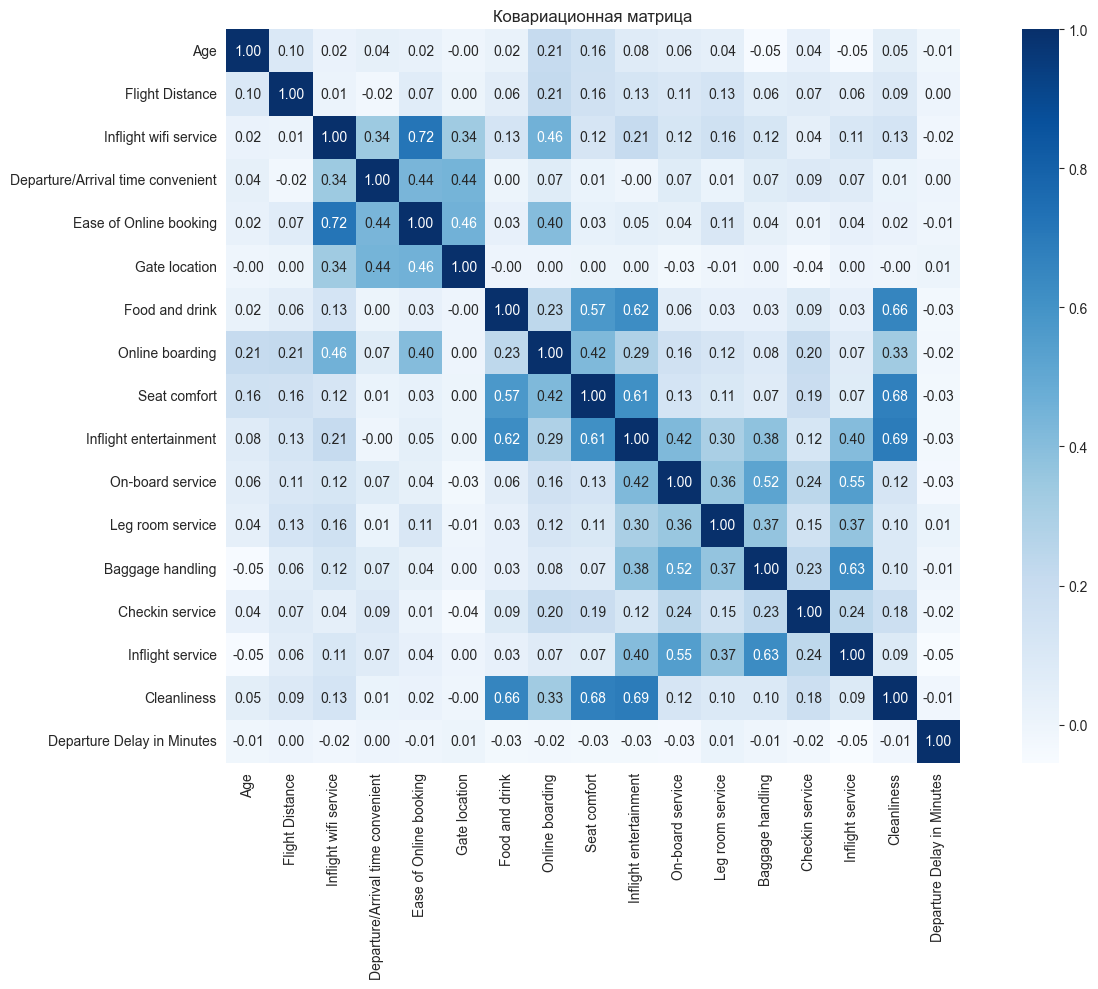

In [4]:
plt.figure(figsize=(14, 10))
sns.heatmap(df_scaled.cov(), annot=True, cmap='Blues', fmt='.2f', square=True)
plt.title('Ковариационная матрица')
plt.tight_layout()
plt.show()

In [5]:
def bartlett_sphericity(df):
    corr = df.corr().values
    n = df.shape[0]
    p = df.shape[1]
    det_corr = np.linalg.det(corr)
    chi2_stat = - (n - 1 - (2*p + 5)/6) * np.log(det_corr)
    df_chi2 = p * (p - 1) // 2
    p_value = 1 - chi2.cdf(chi2_stat, df_chi2)
    return chi2_stat, p_value

def calculate_kmo(df):
    corr = df.corr().values
    inv_corr = np.linalg.pinv(corr)
    n = df.shape[1]
    numer = 0
    denom = 0
    for i in range(n):
        for j in range(n):
            if i != j:
                r2 = corr[i, j]**2
                p2 = -inv_corr[i, j] / np.sqrt(inv_corr[i, i] * inv_corr[j, j])
                p2 = p2**2
                numer += r2
                denom += r2 + p2
    return numer / denom

chi2_value, p_value = bartlett_sphericity(df_scaled)
kmo_total = calculate_kmo(df_scaled)

print(f"Критерий Бартлетта: хи-квадрат = {chi2_value:.2f}, p-value = {p_value:.10f}")
print(f"KMO: {kmo_total:.4f}")

Критерий Бартлетта: хи-квадрат = 621298.46, p-value = 0.0000000000
KMO: 0.7762


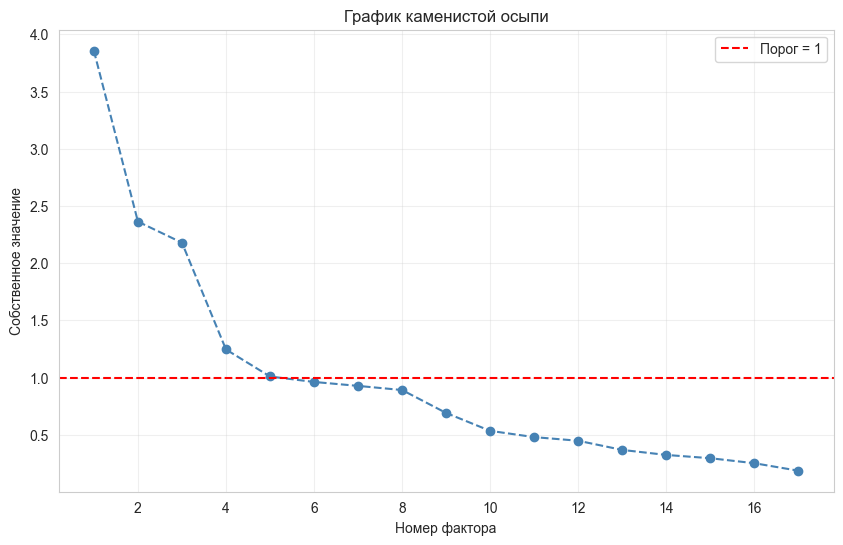

Рекомендуемое число факторов: 5


In [6]:
pca_full = PCA()
pca_full.fit(df_scaled)
eigenvalues = pca_full.explained_variance_

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(eigenvalues)+1), eigenvalues, 'o--', color='steelblue')
plt.axhline(y=1, color='red', linestyle='--', label='Порог = 1')
plt.title('График каменистой осыпи')
plt.xlabel('Номер фактора')
plt.ylabel('Собственное значение')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

n_factors = sum(eigenvalues > 1)
print(f"Рекомендуемое число факторов: {n_factors}")

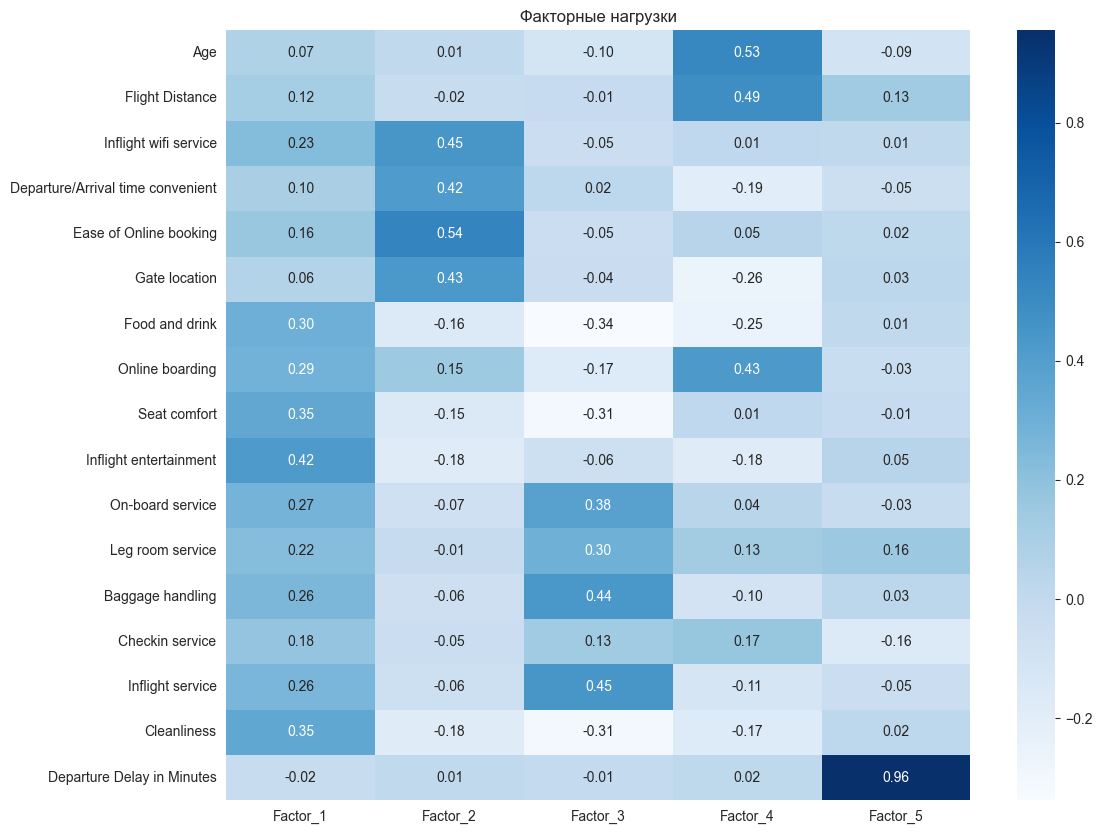

In [7]:
pca = PCA(n_components=n_factors)
pca.fit(df_scaled)

loadings = pca.components_.T
loadings_df = pd.DataFrame(
    loadings,
    index=df_scaled.columns,
    columns=[f'Factor_{i+1}' for i in range(n_factors)]
)

plt.figure(figsize=(12, max(8, n_factors * 2)))
sns.heatmap(loadings_df, annot=True, cmap='Blues', fmt='.2f')
plt.title('Факторные нагрузки')
plt.show()

In [8]:
explained_variance = pca.explained_variance_ratio_
cumulative = np.cumsum(explained_variance)

for i in range(n_factors):
    print(f"Фактор {i+1}: {explained_variance[i]:.4f} (кумулятивно: {cumulative[i]:.4f})")

factor_scores = pca.transform(df_scaled)
print("\nФакторные значения:")
print(pd.DataFrame(factor_scores[:10], columns=[f'Factor_{i+1}' for i in range(n_factors)]).round(4))

Фактор 1: 0.2268 (кумулятивно: 0.2268)
Фактор 2: 0.1390 (кумулятивно: 0.3658)
Фактор 3: 0.1281 (кумулятивно: 0.4940)
Фактор 4: 0.0732 (кумулятивно: 0.5672)
Фактор 5: 0.0593 (кумулятивно: 0.6266)

Факторные значения:
   Factor_1  Factor_2  Factor_3  Factor_4  Factor_5
0    2.1145   -1.2504   -0.2102   -1.9060    0.1617
1   -3.3409    1.2674    1.2250   -0.0971    0.0434
2    2.1095   -1.9169   -0.9250   -0.4038   -0.3912
3   -1.8768    2.5134    0.8253   -1.3953    0.3602
4    0.7633    0.2526   -0.9673    0.8221   -0.5335
5   -2.6178    0.3672    2.5057    0.4880   -0.4776
6   -1.6023    0.2050    1.6148    0.0735   -0.3088
7    3.8016    0.4309    0.4474    0.6711   -0.1015
8   -3.3953   -0.6844   -2.4792    0.7835   -0.6808
9   -1.5076    1.0919    0.3746   -0.3907   -0.3770


In [9]:
for i in range(n_factors):
    factor_col = f'Factor_{i+1}'
    print(f"\nФактор {i+1}:")
    sorted_loadings = loadings_df[factor_col].abs().sort_values(ascending=False).head(5)
    for var, val in sorted_loadings.items():
        actual = loadings_df.loc[var, factor_col]
        print(f"  {var}: {actual:.4f}")


Фактор 1:
  Inflight entertainment: 0.4227
  Cleanliness: 0.3524
  Seat comfort: 0.3461
  Food and drink: 0.3025
  Online boarding: 0.2875

Фактор 2:
  Ease of Online booking: 0.5363
  Inflight wifi service: 0.4495
  Gate location: 0.4302
  Departure/Arrival time convenient: 0.4176
  Inflight entertainment: -0.1789

Фактор 3:
  Inflight service: 0.4473
  Baggage handling: 0.4376
  On-board service: 0.3803
  Food and drink: -0.3379
  Seat comfort: -0.3124

Фактор 4:
  Age: 0.5250
  Flight Distance: 0.4875
  Online boarding: 0.4258
  Gate location: -0.2623
  Food and drink: -0.2541

Фактор 5:
  Departure Delay in Minutes: 0.9551
  Checkin service: -0.1594
  Leg room service: 0.1561
  Flight Distance: 0.1322
  Age: -0.0932


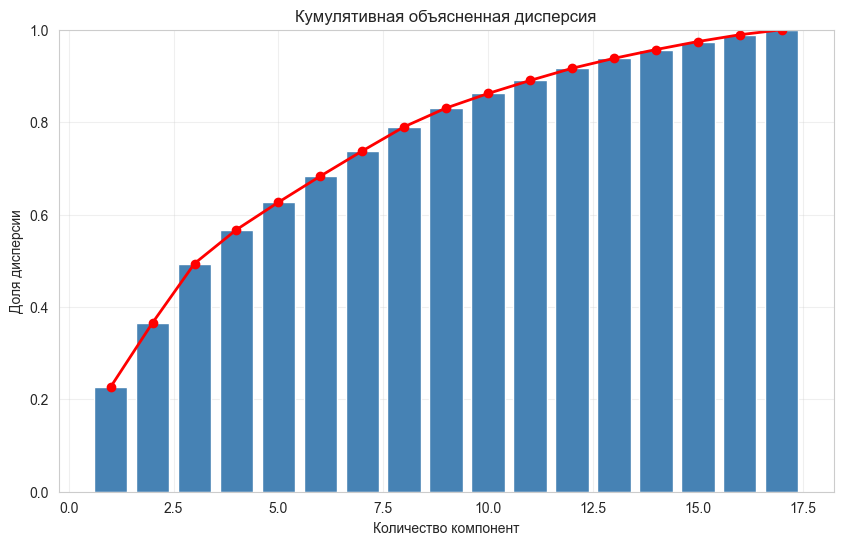

In [10]:
cumulative_var = np.cumsum(eigenvalues) / eigenvalues.sum()

plt.figure(figsize=(10, 6))
plt.bar(range(1, len(cumulative_var)+1), cumulative_var, color='steelblue')
plt.plot(range(1, len(cumulative_var)+1), cumulative_var, 'ro-', linewidth=2)
plt.title('Кумулятивная объясненная дисперсия')
plt.xlabel('Количество компонент')
plt.ylabel('Доля дисперсии')
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.show()

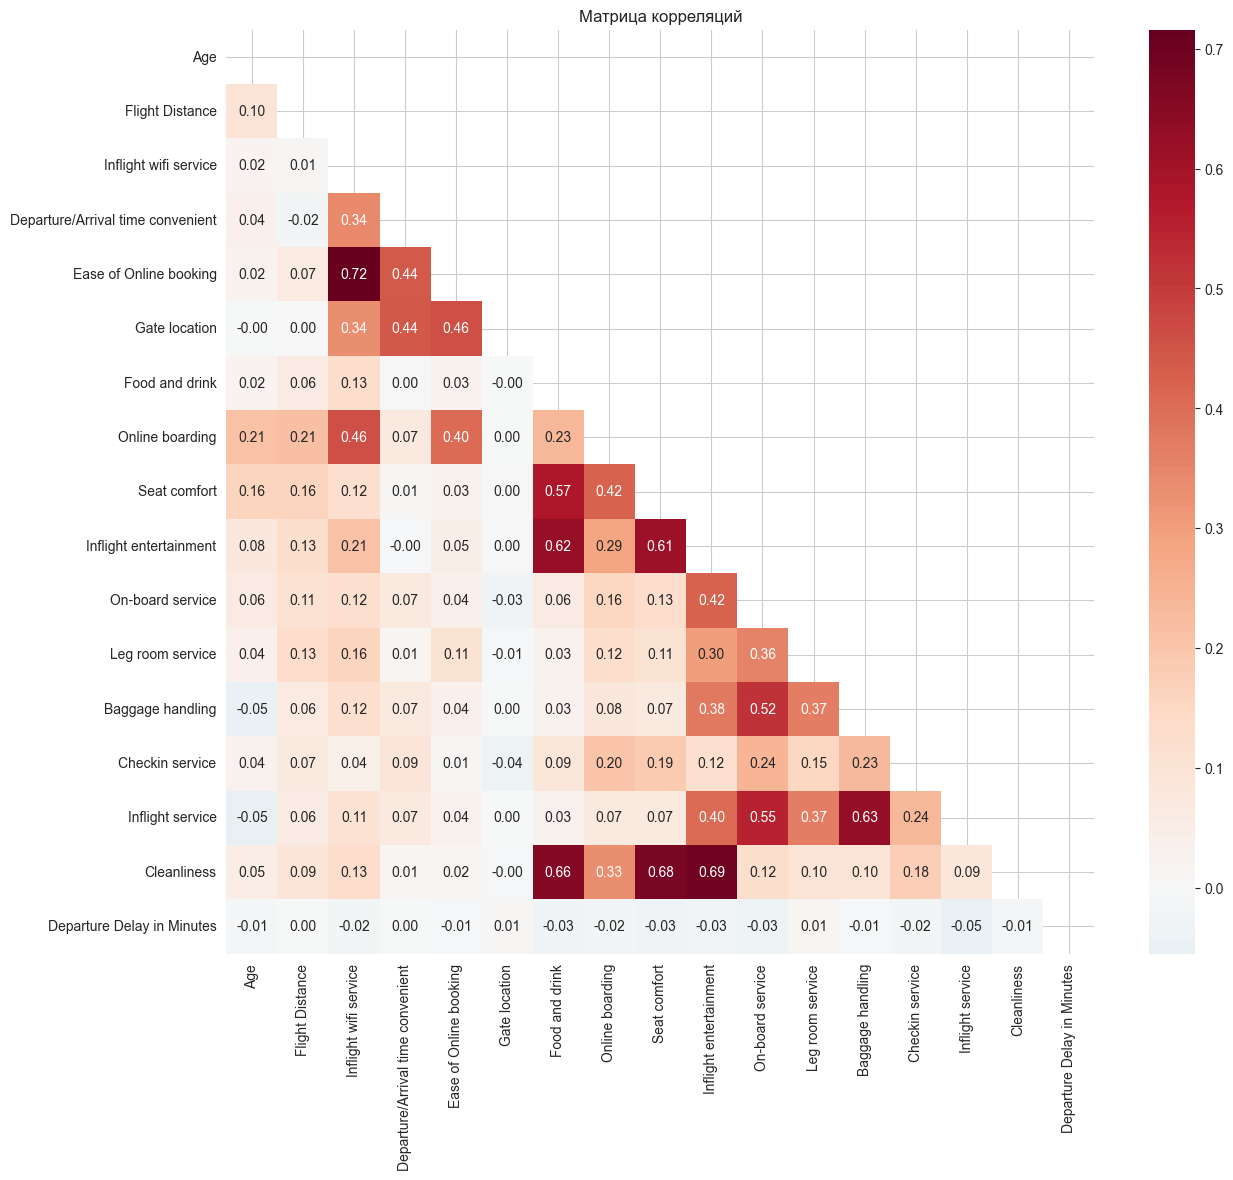

In [11]:
plt.figure(figsize=(14, 12))
corr_matrix = df_numeric.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, cmap='RdBu_r', center=0, fmt='.2f')
plt.title('Матрица корреляций')
plt.show()